# SANPO exploration (chest camera, 5 fps)

Explores the local copy made by `download_from_volume.py`:
- `frames/`: camera images (JPG, native resolution)
- `masks/`: original SANPO masks (PNG): red channel = class id, blue channel = object id
- `index/`: one CSV per walk (session), one row per frame
- `views/<view>/`: our box labels made from the masks by `make_box_view_modal.py`
- `sanpo_meta/`: SANPO's `labelmap.json`, `labeltype.json`, and our split lists

SANPO class types (official `labeltype.json`): **panoptic** = mask + object id, **semantic** = mask only.
Box view `boxes_v1`: 13 panoptic classes (one box per object) + 3 semantic classes (one box per blob of touching pixels).

Run the cells in order.

## 0. Packages (only needed on Modal Jupyter)

Run this cell once when the notebook runs on Modal (`modal launch jupyter`); skip it on your PC.

In [ ]:
%pip install -q pandas matplotlib pyyaml pillow numpy opencv-python-headless

## 1. Settings

In [5]:
from pathlib import Path

# Works in two places:
#  - on Modal (`modal launch jupyter --volume sanpo --mount <this folder>`): the notebook is in "mount/",
#    the Volume is in "volume/" next to it
#  - on this PC, after download_from_volume.py: ../../data/sanpo
CANDIDATES = [Path("../volume/sanpo_real_chest_5fps").resolve(), Path("../../data/sanpo/sanpo_real_chest_5fps").resolve()]
DATASET_DIR = next((p for p in CANDIDATES if p.exists()), CANDIDATES[-1])
VIEW_NAME = "boxes_v1"
SPLITS = ["train", "val", "test"]

VIEW_DIR = DATASET_DIR / "views" / VIEW_NAME
print(DATASET_DIR, "exists:", DATASET_DIR.exists())
print(VIEW_DIR, "exists:", VIEW_DIR.exists())

D:\My Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_chest_5fps exists: True
D:\My Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_chest_5fps\views\boxes_v1 exists: True


## 2. Imports

In [6]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

## 3. SANPO classes: id, name, official type, and how the box view uses them

In [9]:
labelmap = json.loads((DATASET_DIR / "sanpo_meta" / "labelmap.json").read_text())    # name -> id
labeltype = json.loads((DATASET_DIR / "sanpo_meta" / "labeltype.json").read_text())  # name -> panoptic/semantic
view_cfg = yaml.safe_load((VIEW_DIR / "view.yaml").read_text())
view_names = view_cfg["names"]
if isinstance(view_names, dict):
    view_names = [view_names[i] for i in sorted(view_names)]

def view_use(name):
    if name in view_cfg["panoptic_classes"]:
        return "box per object"
    if name in view_cfg["semantic_blob_classes"]:
        return "box per blob"
    return "not used"

classes = pd.DataFrame([{"sanpo_id": i, "class": n, "sanpo_type": labeltype.get(n, "?"), "box_view": view_use(n)}
                        for n, i in sorted(labelmap.items(), key=lambda kv: kv[1])])
id_to_name = dict(zip(classes["sanpo_id"], classes["class"]))
print(classes["box_view"].value_counts().to_string())
classes

box_view
not used          15
box per object    13
box per blob       3


,sanpo_id,class,sanpo_type,box_view
0,0,unlabeled,semantic,not used
1,1,road,semantic,not used
2,2,curb,semantic,not used
3,3,sidewalk,semantic,not used
4,4,guard rail/road barrier,semantic,box per blob
5,5,crosswalk,panoptic,box per object
6,6,paved trail,semantic,not used
7,7,building,semantic,not used
8,8,wall/fence,semantic,box per blob
9,9,hand rail,semantic,not used


## 4. Frames and sessions per split

In [12]:
index = pd.concat([pd.read_csv(p) for p in sorted((DATASET_DIR / "index").glob("*.csv"))], ignore_index=True)
index["resolution"] = index["width"].astype(str) + "x" + index["height"].astype(str)

per_split = index.groupby("split").agg(sessions=("session", "nunique"), frames=("frame_id", "count")).reindex(SPLITS)
per_split["share_of_frames_%"] = (100 * per_split["frames"] / per_split["frames"].sum()).round(1)
FPS = 5  # frames kept per second of video (15 fps / stride 3)

def hms(seconds):
    seconds = int(round(seconds))
    return f"{seconds // 3600}h {seconds % 3600 // 60:02d}m {seconds % 60:02d}s"

per_split["video_duration"] = (per_split["frames"] / FPS).map(hms)
per_split.loc["total"] = [per_split["sessions"].sum(), per_split["frames"].sum(), 100.0,
                          hms(per_split["frames"].sum() / FPS)]
print(per_split, "\n")
print("Resolutions:\n", index["resolution"].value_counts().to_string(), "\n")
per_session = index.groupby("session").size()
print("Frames per session:\n", per_session.describe().round(1).to_string())
print("Seconds per session (frames / 5 fps):\n", (per_session / FPS).describe().round(1).to_string())

# Sanity: every indexed file exists locally
missing_frames = sum(not (DATASET_DIR / p).exists() for p in index["frame"])
missing_masks = sum(not (DATASET_DIR / p).exists() for p in index["mask"])
print(f"\nmissing frame files: {missing_frames} | missing mask files: {missing_masks}")

       sessions  frames  share_of_frames_% video_duration
split                                                    
train       102   16449               69.0     0h 54m 50s
val          14    2297                9.6     0h 07m 39s
test         30    5107               21.4     0h 17m 01s
total       146   23853              100.0     1h 19m 31s 

Resolutions:
 resolution
2208x1242    23853 

Frames per session:
 count    146.0
mean     163.4
std       52.2
min       22.0
25%      140.0
50%      149.5
75%      190.5
max      306.0
Seconds per session (frames / 5 fps):
 count    146.0
mean      32.7
std       10.4
min        4.4
25%       28.0
50%       29.9
75%       38.1
max       61.2

missing frame files: 0 | missing mask files: 0


## 5. Load the boxes of the view

One row per box, in pixels. `source` = `panoptic` (box per object id) or `blob` (box per group of touching pixels).

In [20]:
boxes = pd.concat([pd.read_csv(p) for p in sorted((VIEW_DIR / "boxes").rglob("*.csv"))], ignore_index=True)
boxes["w"] = boxes["x2"] - boxes["x1"]
boxes["h"] = boxes["y2"] - boxes["y1"]
boxes["area_frac"] = boxes["w"] * boxes["h"] / (boxes["width"] * boxes["height"])  # box area / image area
boxes["fill"] = boxes["pixels"] / (boxes["w"] * boxes["h"])  # share of the box covered by the object's pixels
print(f"boxes: {len(boxes):,} | frames: {len(index):,} | mean boxes per frame: {len(boxes) / len(index):.1f}")
# Per split and source (panoptic / blob):
#   boxes: count (share of that split's boxes)
#   frames: frames with at least one such box, and the video they cover (frames / FPS)
# Note: a frame can have both panoptic and blob boxes, so frames / durations overlap between the two rows.
# FPS and hms() are defined in section 4.
by_source = boxes.groupby(["split", "source"]).agg(n_boxes=("image", "size"), frames=("image", "nunique"))
split_boxes = by_source.groupby(level="split")["n_boxes"].transform("sum")
by_source["boxes"] = (by_source["n_boxes"].astype(str) + " ("
                      + (100 * by_source["n_boxes"] / split_boxes).round(1).astype(str) + "%)")
by_source["video_duration"] = (by_source["frames"] / FPS).map(hms)
by_source["share_of_split_frames_%"] = (
    100 * by_source["frames"] / by_source.index.get_level_values("split").map(index.groupby("split").size())
).round(1)
by_source[["boxes", "frames", "video_duration", "share_of_split_frames_%"]].reindex(SPLITS, level="split")

boxes: 356,392 | frames: 23,853 | mean boxes per frame: 14.9


boxes  frames video_duration  share_of_split_frames_%
split source                                                                  
train blob       38051 (15.0%)   11827     0h 39m 25s                     71.9
      panoptic  215375 (85.0%)   16210     0h 54m 02s                     98.5
val   blob        5743 (16.1%)    2007     0h 06m 41s                     87.4
      panoptic   29991 (83.9%)    2276     0h 07m 35s                     99.1
test  blob       10500 (15.6%)    4017     0h 13m 23s                     78.7
      panoptic   56732 (84.4%)    4974     0h 16m 35s                     97.4

## 6. Boxes per class, per split

In [21]:
box_counts = boxes.pivot_table(index="class", columns="split", values="image", aggfunc="count", fill_value=0)
box_counts = box_counts.reindex(columns=SPLITS, fill_value=0).reindex(view_names, fill_value=0)
box_counts["total"] = box_counts.sum(axis=1)
box_counts["share_%"] = (100 * box_counts["total"] / box_counts["total"].sum()).round(2)
box_counts["source"] = [view_use(n).replace("box per ", "") for n in box_counts.index]
box_counts.sort_values("total", ascending=False)

split,train,val,test,total,share_%,source
class,,,,,,
obstacle,64162,8055,19302,91519,25.68,object
vehicle,46075,8524,11023,65622,18.41,object
pedestrian,38072,2947,8720,49739,13.96,object
wall/fence,33688,5593,9173,48454,13.60,blob
tree,30894,3658,6439,40991,11.50,object
pole,14392,888,5324,20604,5.78,object
crosswalk,4464,678,1569,6711,1.88,object
traffic sign,4619,914,1009,6542,1.84,object
bike rack,4415,1046,883,6344,1.78,object


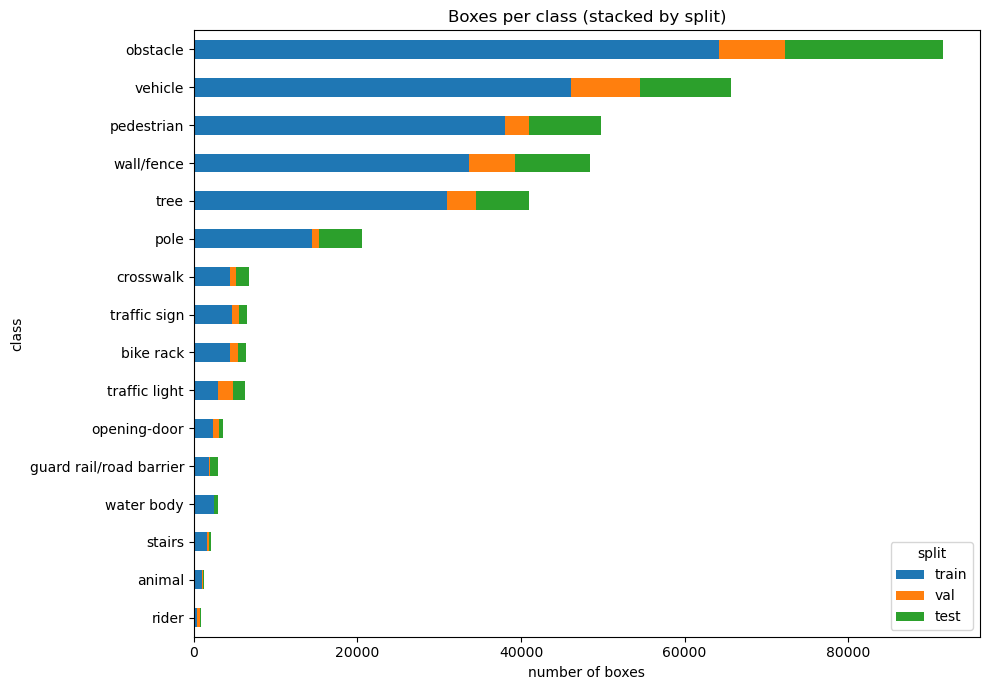

In [22]:
ax = box_counts.sort_values("total")[SPLITS].plot(kind="barh", stacked=True, figsize=(10, 7))
ax.set_xlabel("number of boxes")
ax.set_title("Boxes per class (stacked by split)")
plt.tight_layout()
plt.show()

## 7. Frames containing each class, per split

A frame with 5 pedestrians counts once here. Classes with few **test** frames give noisy test scores.

In [23]:
frame_counts = (boxes.drop_duplicates(["split", "image", "class"])
                .pivot_table(index="class", columns="split", values="image", aggfunc="count", fill_value=0)
                .reindex(columns=SPLITS, fill_value=0).reindex(view_names, fill_value=0))
frame_counts["total"] = frame_counts.sum(axis=1)
frame_counts["share_of_all_frames_%"] = (100 * frame_counts["total"] / len(index)).round(1)
frame_counts["few_test_frames(<50)"] = frame_counts["test"] < 50
frame_counts.sort_values("total", ascending=False)

split,train,val,test,total,share_of_all_frames_%,few_test_frames(<50)
class,,,,,,
obstacle,13859,2043,4188,20090,84.2,False
wall/fence,11693,2007,3838,17538,73.5,False
vehicle,10252,1852,2743,14847,62.2,False
pedestrian,10603,1070,2927,14600,61.2,False
tree,10160,1512,2513,14185,59.5,False
pole,5165,529,1867,7561,31.7,False
crosswalk,3105,502,1143,4750,19.9,False
traffic sign,2648,508,645,3801,15.9,False
bike rack,2335,436,494,3265,13.7,False


## 8. Boxes per frame and empty frames

         count   mean   std  min   25%   50%   75%   max
split                                                   
train  16449.0  15.41  8.87  0.0   9.0  14.0  21.0  60.0
val     2297.0  15.56  6.83  0.0  10.0  16.0  20.0  41.0
test    5107.0  13.16  7.52  0.0   7.0  12.0  18.0  41.0

frames with no boxes: {'train': 80, 'val': 4, 'test': 8}


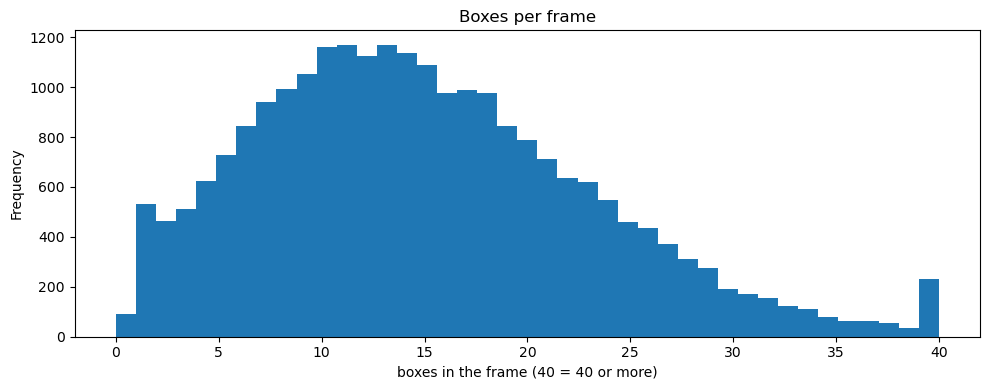

In [24]:
per_frame = boxes.groupby(["split", "image"]).size()
all_frames = index.assign(image=index["frame"].map(lambda p: Path(p).name)).set_index(["split", "image"])
counts = per_frame.reindex(all_frames.index, fill_value=0)
print(counts.groupby(level="split").describe().reindex(SPLITS).round(2))
print("\nframes with no boxes:", counts.eq(0).groupby(level="split").sum().reindex(SPLITS).to_dict())

ax = counts.clip(upper=40).plot(kind="hist", bins=41, figsize=(10, 4))
ax.set_xlabel("boxes in the frame (40 = 40 or more)")
ax.set_title("Boxes per frame")
plt.tight_layout()
plt.show()

## 9. Box sizes and how well boxes fit

- `area_frac`: box area / image area. Size buckets: small < 1%, medium 1 to 10%, large > 10%.
- `fill`: share of the box actually covered by the object's pixels. Low fill = mostly background inside the box
  (typical for thin or diagonal things, and for blobs that merged several objects).

In [25]:
boxes["size"] = pd.cut(boxes["area_frac"], bins=[0, 0.01, 0.10, 1.0001],
                       labels=["small(<1%)", "medium(1-10%)", "large(>10%)"], include_lowest=True)
size_table = boxes.pivot_table(index="class", columns="size", values="image", aggfunc="count",
                               fill_value=0, observed=False).reindex(view_names, fill_value=0)
size_table["median_area_%"] = (100 * boxes.groupby("class")["area_frac"].median()).round(2)
size_table["median_fill_%"] = (100 * boxes.groupby("class")["fill"].median()).round(1)
size_table.sort_values("median_area_%")

size,small(<1%),medium(1-10%),large(>10%),median_area_%,median_fill_%
class,,,,,
traffic sign,6234,271,37,0.08,75.6
traffic light,6101,136,5,0.08,72.2
rider,719,178,14,0.25,62.2
pole,15769,4454,381,0.27,49.7
bike rack,4751,1501,92,0.33,56.4
guard rail/road barrier,1993,633,305,0.34,66.6
animal,956,231,5,0.35,60.8
water body,1898,793,218,0.40,59.6
vehicle,45271,17510,2841,0.42,65.8


## 10. Pixel share of every SANPO class (all 31, from a sample of masks)

Shows how much of the image each class covers, including the classes not used as boxes (curb, road, sidewalk, ...).

In [28]:
N_MASKS = 300  # random masks to read (more = slower, more exact)
sample = index.sample(min(N_MASKS, len(index)), random_state=0)
pixel_counts = np.zeros(256, dtype=np.int64)
frames_with = np.zeros(256, dtype=np.int64)
for p in sample["mask"]:
    sem = np.asarray(Image.open(DATASET_DIR / p).convert("RGB"))[..., 0]
    c = np.bincount(sem.ravel(), minlength=256)
    pixel_counts += c
    frames_with += c > 0
pix = classes.assign(
    pct_of_all_pixels=lambda d: (100 * pixel_counts[d["sanpo_id"]] / pixel_counts.sum()).round(2),
    pct_of_frames_containing_it=lambda d: (100 * frames_with[d["sanpo_id"]] / len(sample)).round(1),
)
pix.sort_values("pct_of_all_pixels", ascending=False)

,sanpo_id,class,sanpo_type,box_view,pct_of_all_pixels,pct_of_frames_containing_it
3,3,sidewalk,semantic,not used,21.87,64.0
6,6,paved trail,semantic,not used,13.75,44.3
7,7,building,semantic,not used,11.60,81.0
8,8,wall/fence,semantic,box per blob,7.86,72.3
29,29,vegetation,semantic,not used,7.15,76.0
20,20,obstacle,panoptic,box per object,6.63,84.3
1,1,road,semantic,not used,6.08,61.3
30,30,terrain,semantic,not used,5.02,43.7
21,21,vehicle,panoptic,box per object,3.74,66.0
12,12,pedestrian,panoptic,box per object,3.02,58.7


## 11. Check: label files match the boxes table

Compares the number of lines in a sample of YOLO label files with the boxes CSV.

In [29]:
N_CHECK = 500
check = index.sample(min(N_CHECK, len(index)), random_state=1)
mismatch = 0
for _, r in check.iterrows():
    label = VIEW_DIR / "labels" / r["split"] / (Path(r["frame"]).stem + ".txt")
    n_lines = len([l for l in label.read_text().splitlines() if l.strip()]) if label.exists() else -1
    n_rows = int(per_frame.get((r["split"], Path(r["frame"]).name), 0))
    mismatch += n_lines != n_rows
print(f"checked {len(check)} frames | mismatches: {mismatch}")

checked 500 frames | mismatches: 0


## 12. Random frames with boxes (manual check)

New random frames every run.
- Boxes: **green** = panoptic (box per object), **orange** = blob (box per group of touching pixels).
- `CLASS_TO_SHOW`: None = any frame, or a class name (e.g. `"wall/fence"`) to pick frames with that class
  (its boxes are drawn thicker, in red).
- `SHOW_MASK = True`: also shows the colored SANPO mask next to each frame.

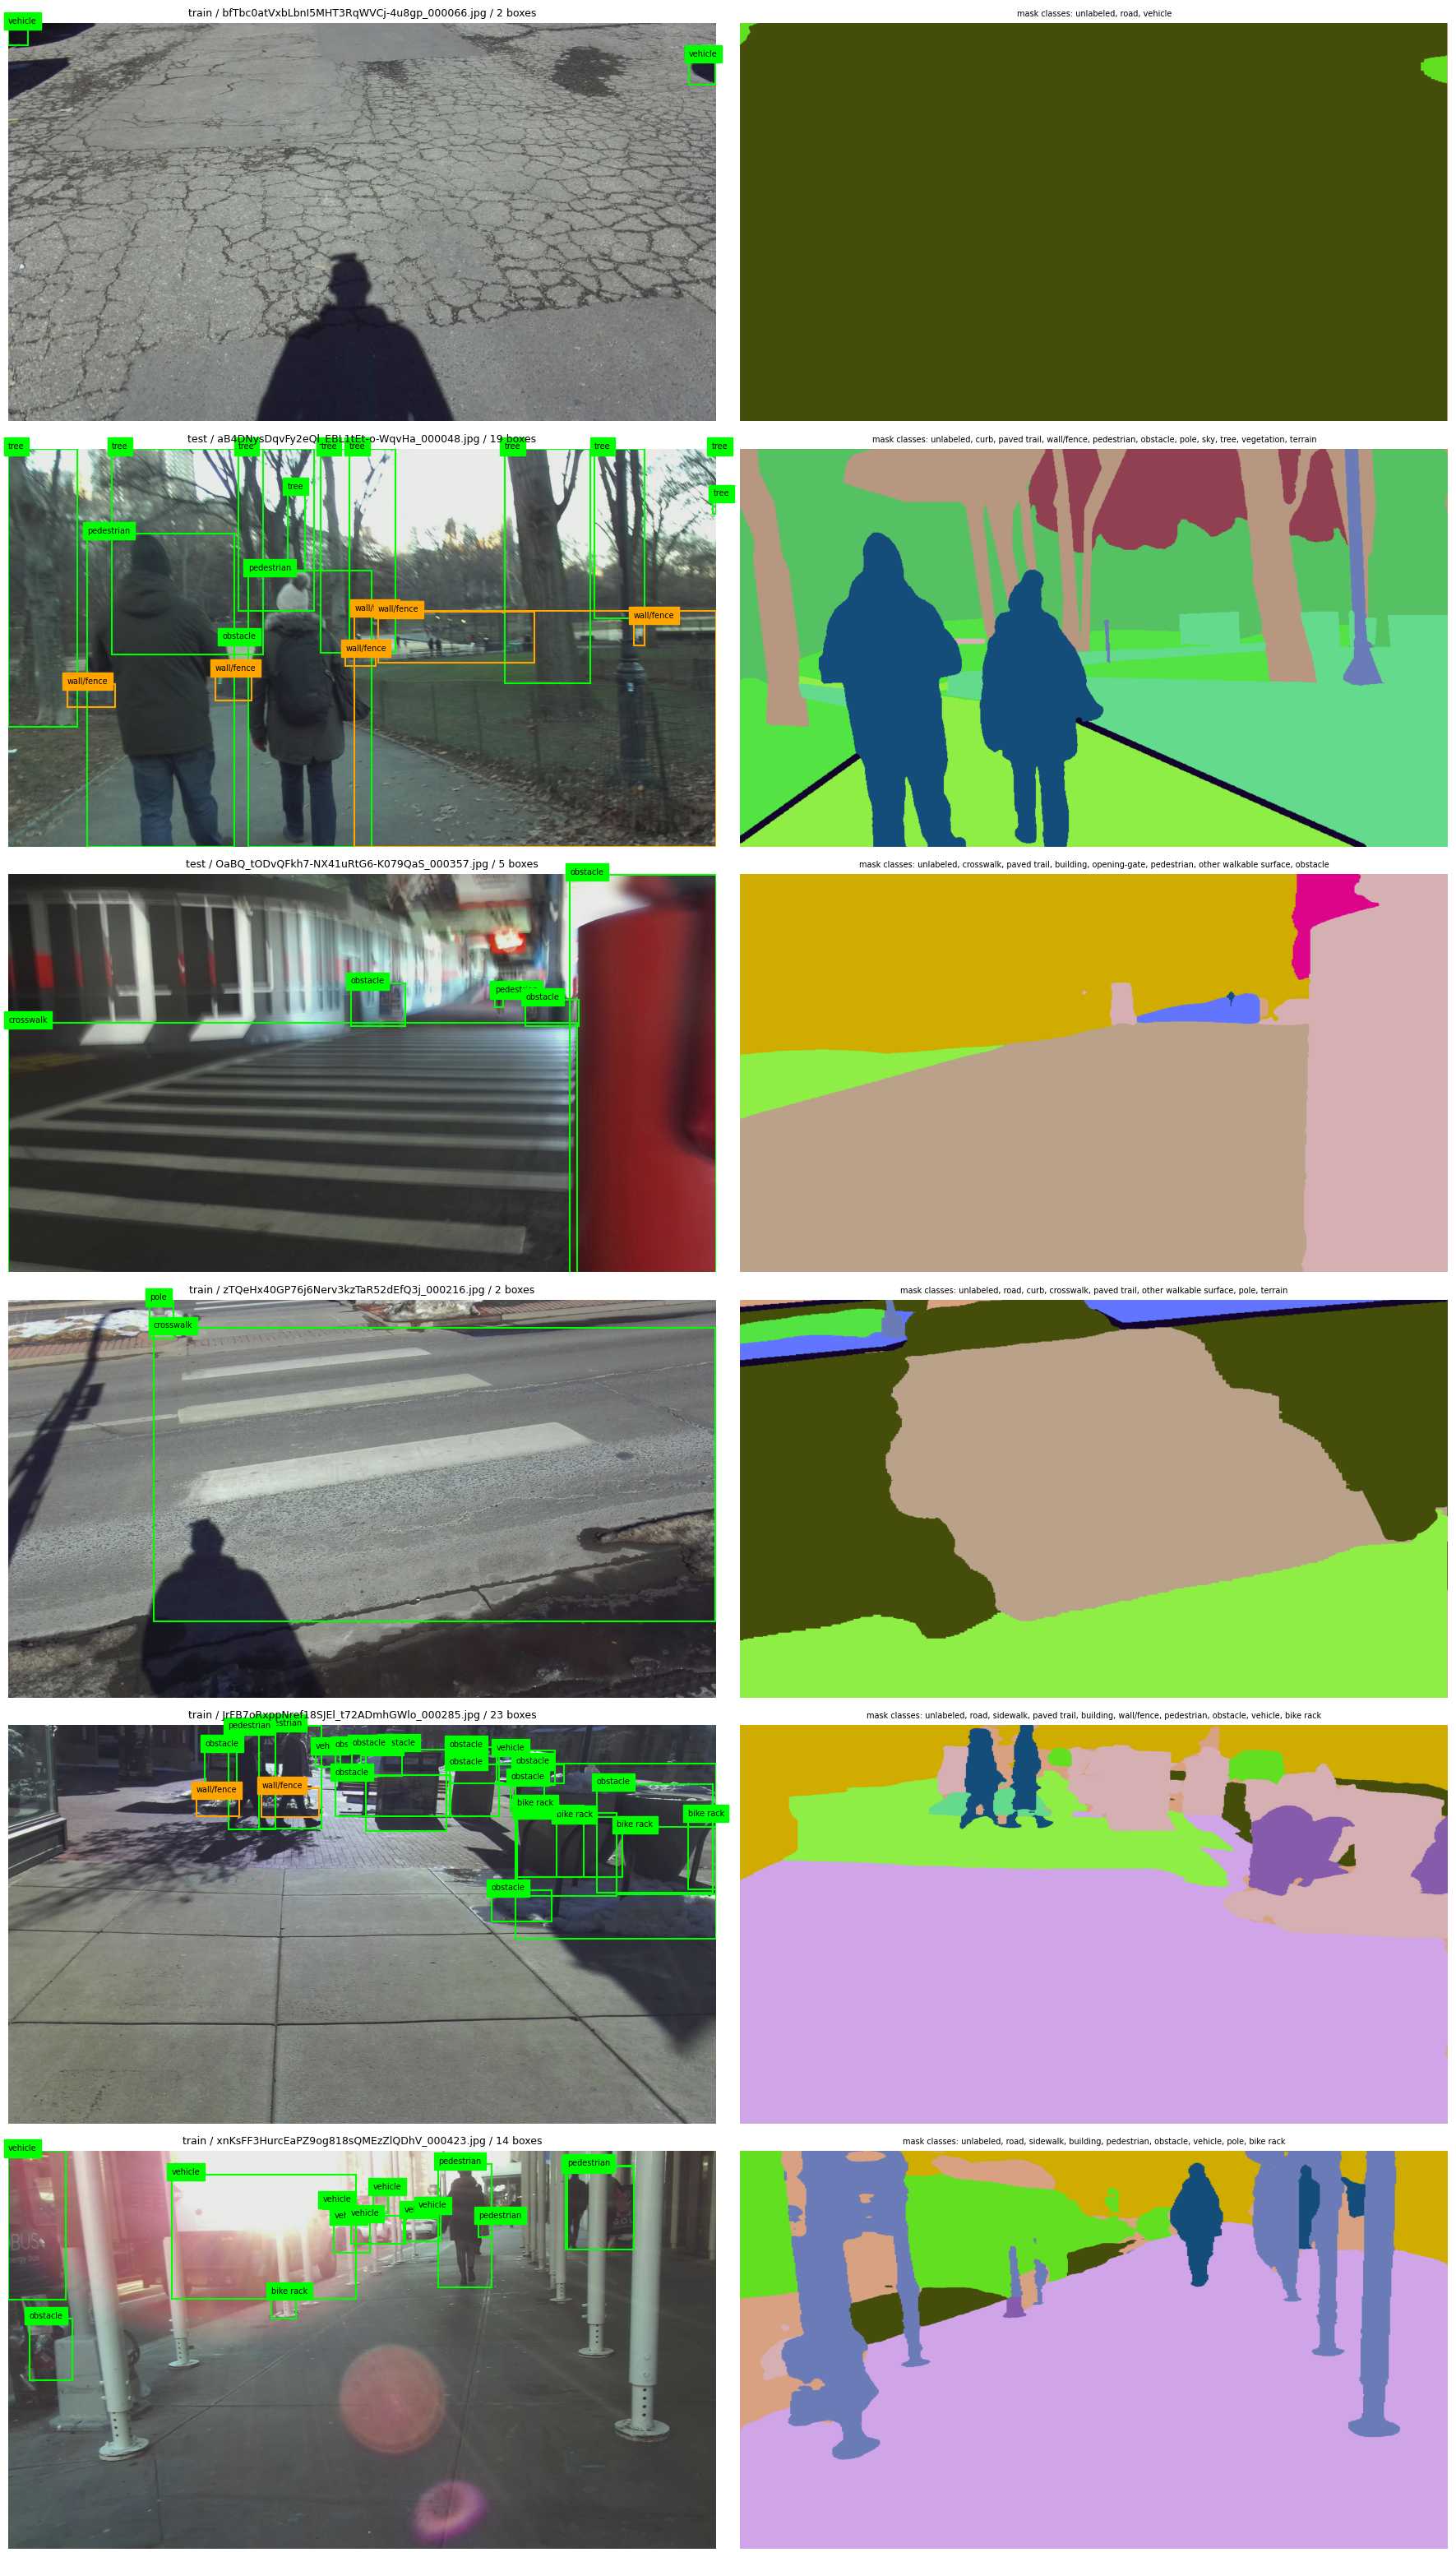

In [32]:
CLASS_TO_SHOW = None   # None = all classes, or a name from section 3 (e.g. "pole", "wall/fence")
SPLIT_TO_SHOW = None   # None = all splits, or "train" / "val" / "test"
N_EXAMPLES = 6
SHOW_MASK = True

pool = index.assign(image=index["frame"].map(lambda p: Path(p).name))
if SPLIT_TO_SHOW:
    pool = pool[pool["split"] == SPLIT_TO_SHOW]
if CLASS_TO_SHOW:
    keep = boxes.loc[boxes["class"] == CLASS_TO_SHOW, ["split", "image"]].drop_duplicates()
    pool = pool.merge(keep, on=["split", "image"])
chosen = pool.sample(min(N_EXAMPLES, len(pool)))  # no seed: different frames every run

palette = np.random.default_rng(0).integers(0, 255, size=(256, 3)).astype(np.uint8)  # one color per SANPO class
cols = 2 if SHOW_MASK else 3
rows = len(chosen) if SHOW_MASK else int(np.ceil(len(chosen) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(9 * cols, 5.2 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for k, (_, row) in enumerate(chosen.iterrows()):
    ax = axes[k, 0] if SHOW_MASK else axes.ravel()[k]
    ax.imshow(Image.open(DATASET_DIR / row["frame"]))
    fb = boxes[(boxes["split"] == row["split"]) & (boxes["image"] == row["image"])]
    for _, b in fb.iterrows():
        highlight = CLASS_TO_SHOW is not None and b["class"] == CLASS_TO_SHOW
        color = "red" if highlight else ("lime" if b["source"] == "panoptic" else "orange")
        ax.add_patch(plt.Rectangle((b["x1"], b["y1"]), b["w"], b["h"], fill=False, color=color, lw=3 if highlight else 1.5))
        ax.text(b["x1"], b["y1"], b["class"], color="black", fontsize=7, backgroundcolor=color)
    ax.set_title(f"{row['split']} / {row['image']} / {len(fb)} boxes", fontsize=9)
    if SHOW_MASK:
        sem = np.asarray(Image.open(DATASET_DIR / row["mask"]).convert("RGB"))[..., 0]
        axes[k, 1].imshow(palette[sem])
        present = [id_to_name.get(int(i), str(i)) for i in np.unique(sem)]
        axes[k, 1].set_title("mask classes: " + ", ".join(present), fontsize=7, wrap=True)
plt.tight_layout()
plt.show()

## 13. Blobs: before and after (manual check)

For random frames that contain a blob class (guard rail, wall/fence, water body), one row per frame:
1. **Frame**: the camera image.
2. **Before**: SANPO's mask pixels of the blob classes only (no object ids, just "this pixel is fence").
3. **Blobs**: the same pixels split into blobs (touching pixels = one blob), each blob in its own color.
   Blobs smaller than the view's minimum area (dropped as noise) are shown in gray.
4. **After**: the frame with the blob boxes from the view.

New random frames every run. Set `BLOB_CLASS` to look at one class only.

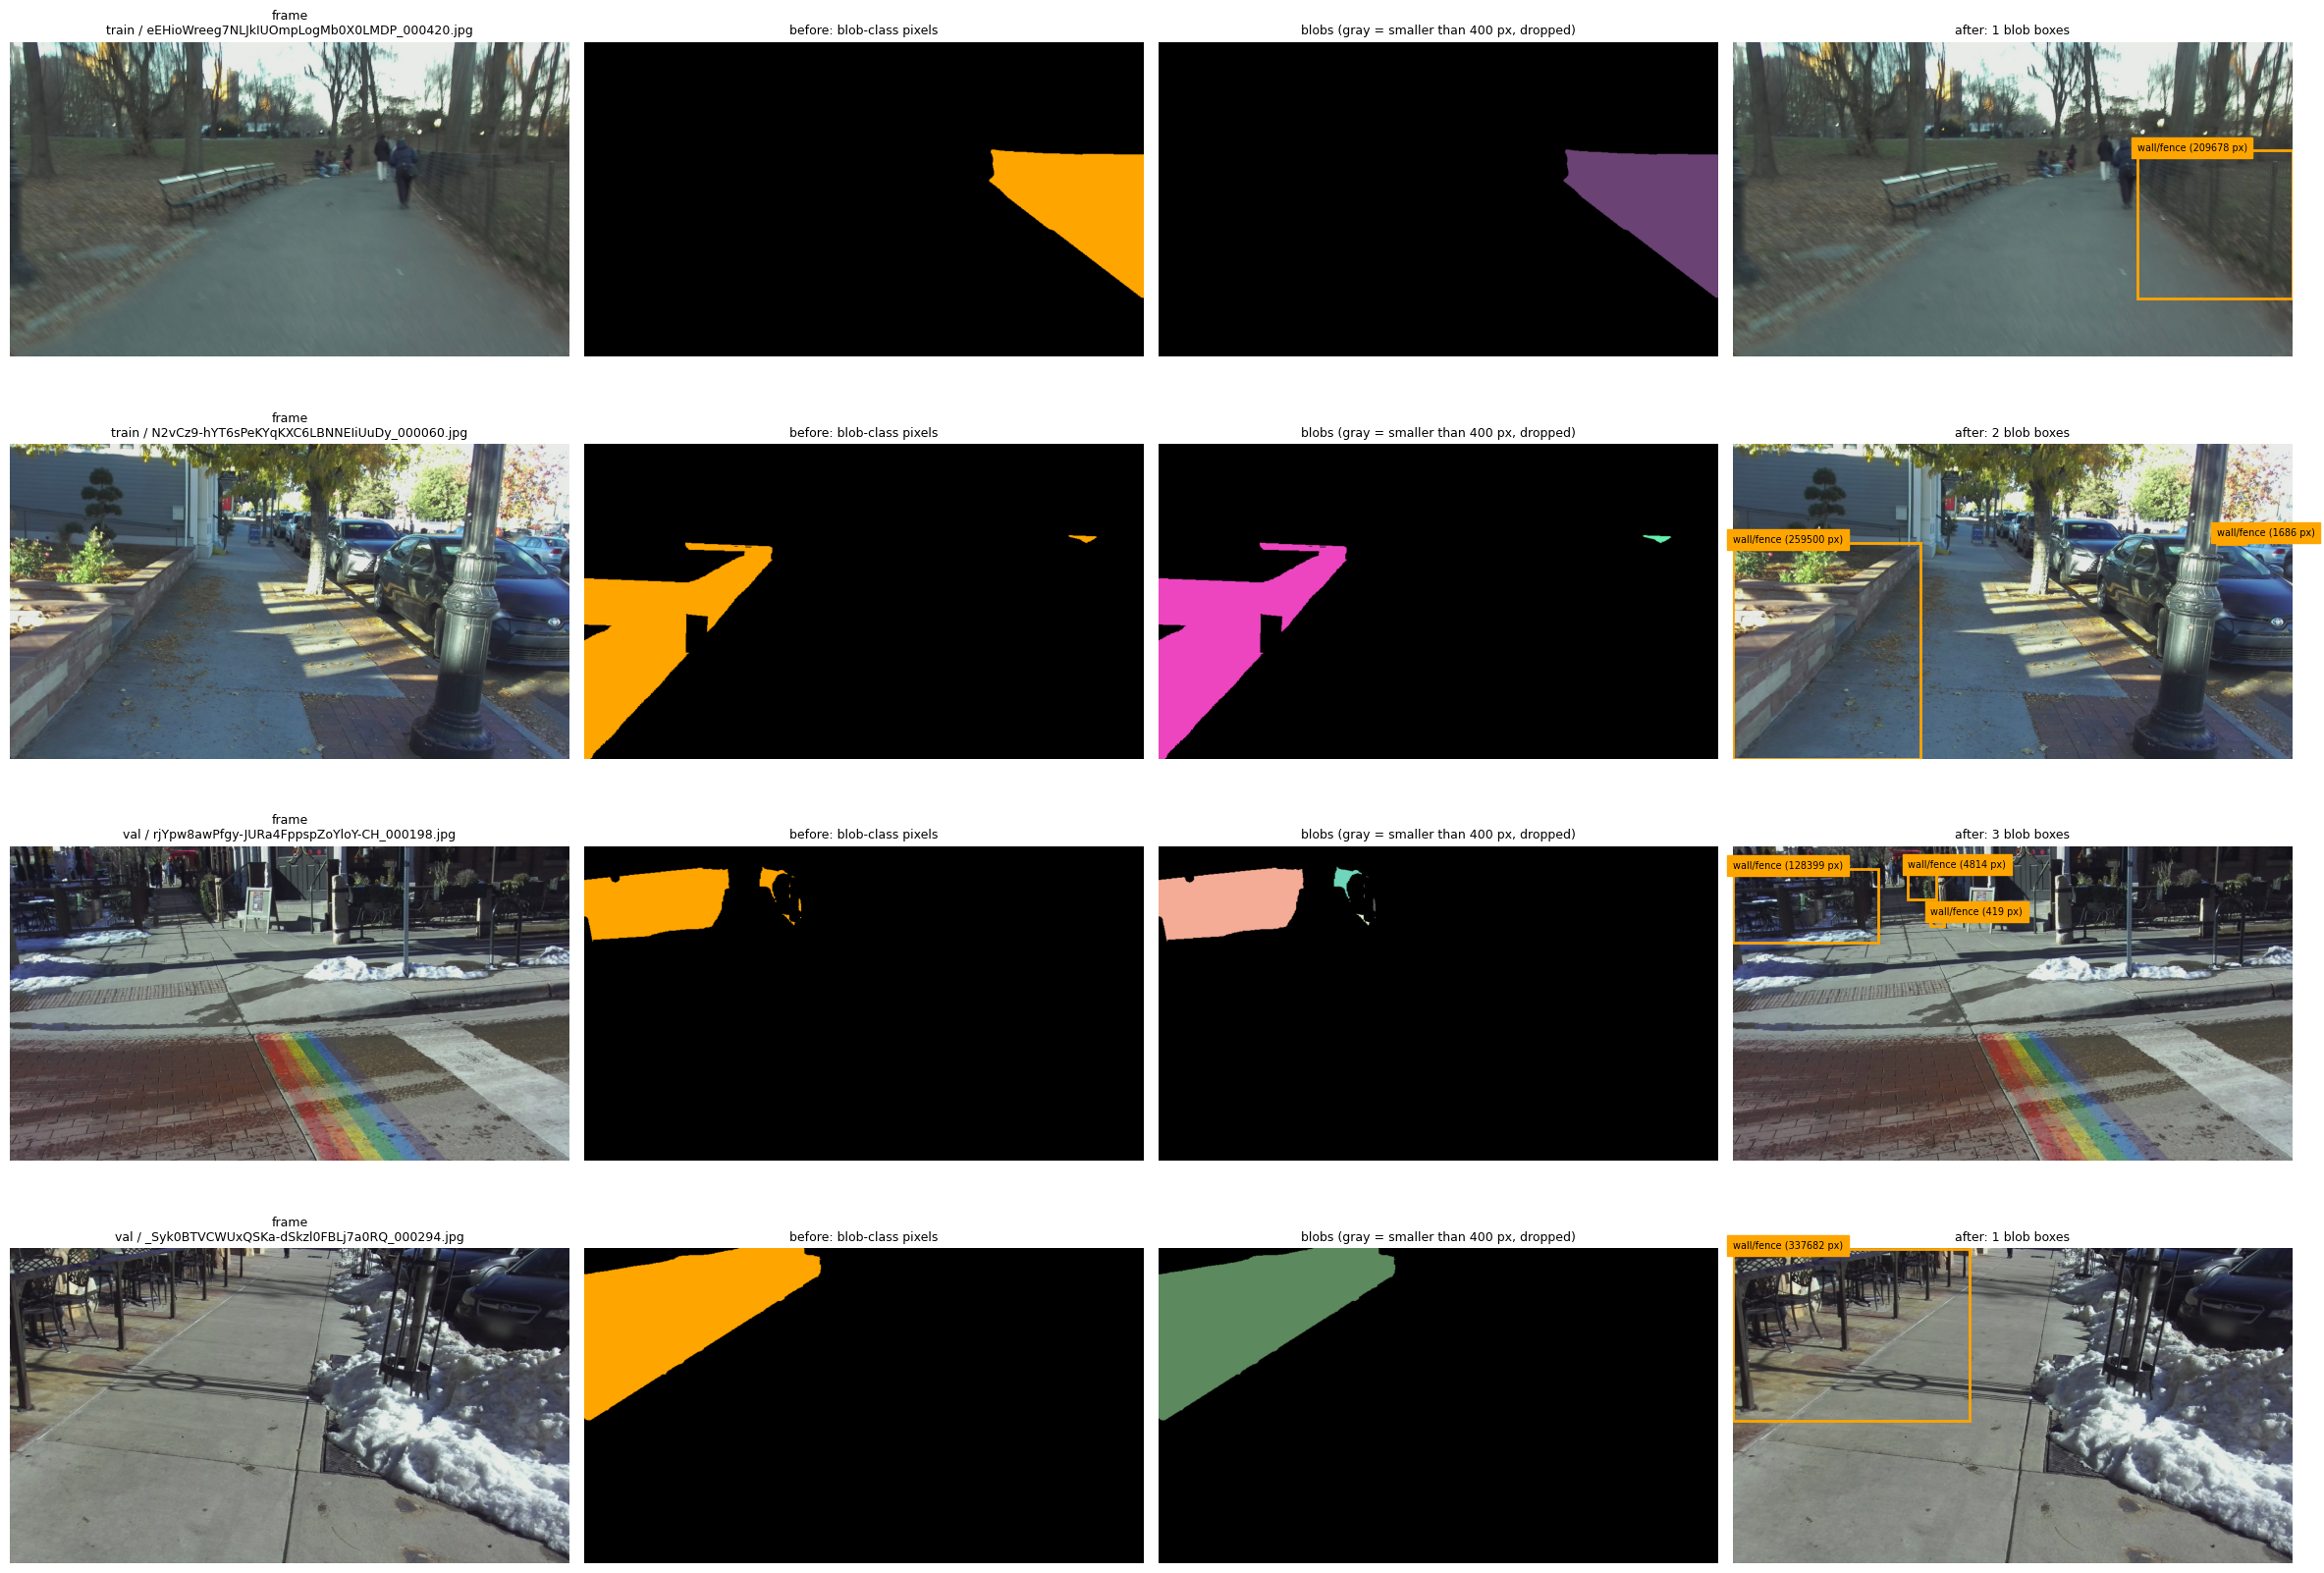

In [35]:
import cv2

BLOB_CLASS = None   # None = any blob class, or "guard rail/road barrier" / "wall/fence" / "water body"
SPLIT_TO_SHOW = None
N_EXAMPLES = 4

blob_classes = [BLOB_CLASS] if BLOB_CLASS else view_cfg["semantic_blob_classes"]
min_area = view_cfg["min_blob_area_px"]
pool = boxes[(boxes["source"] == "blob") & boxes["class"].isin(blob_classes)]
if SPLIT_TO_SHOW:
    pool = pool[pool["split"] == SPLIT_TO_SHOW]
chosen = pool[["split", "image"]].drop_duplicates().sample(min(N_EXAMPLES, pool["image"].nunique()))
frame_lookup = index.assign(image=index["frame"].map(lambda p: Path(p).name)).set_index(["split", "image"])

rng = np.random.default_rng()
class_colors = {"guard rail/road barrier": "magenta", "wall/fence": "orange", "water body": "cyan"}
fig, axes = plt.subplots(len(chosen), 4, figsize=(24, 4.2 * len(chosen)), squeeze=False)
for row_axes, (_, r) in zip(axes, chosen.iterrows()):
    info = frame_lookup.loc[(r["split"], r["image"])]
    frame = np.asarray(Image.open(DATASET_DIR / info["frame"]).convert("RGB"))
    sem = np.asarray(Image.open(DATASET_DIR / info["mask"]).convert("RGB"))[..., 0]

    before = np.zeros_like(frame)              # blob-class pixels colored by class
    blobs_img = np.zeros_like(frame)           # each blob in its own random color
    for name in blob_classes:
        is_class = sem == labelmap[name]
        before[is_class] = (np.array(plt.matplotlib.colors.to_rgb(class_colors.get(name, "white"))) * 255).astype(np.uint8)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(is_class.astype(np.uint8), connectivity=8)
        for k in range(1, n):
            color = rng.integers(60, 255, size=3) if stats[k, cv2.CC_STAT_AREA] >= min_area else np.array([90, 90, 90])
            blobs_img[labels == k] = color

    fb = boxes[(boxes["split"] == r["split"]) & (boxes["image"] == r["image"]) & (boxes["source"] == "blob")
               & boxes["class"].isin(blob_classes)]
    titles = ["frame", "before: blob-class pixels", f"blobs (gray = smaller than {min_area} px, dropped)",
              f"after: {len(fb)} blob boxes"]
    for ax, img, title in zip(row_axes, [frame, before, blobs_img, frame], titles):
        ax.imshow(img)
        ax.set_title(f"{title}\n{r['split']} / {r['image']}" if title == "frame" else title, fontsize=9)
        ax.axis("off")
    for _, b in fb.iterrows():
        c = class_colors.get(b["class"], "white")
        row_axes[3].add_patch(plt.Rectangle((b["x1"], b["y1"]), b["w"], b["h"], fill=False, color=c, lw=2))
        row_axes[3].text(b["x1"], b["y1"], f"{b['class']} ({b['pixels']} px)", color="black", fontsize=7, backgroundcolor=c)
plt.tight_layout()
plt.show()